# **Supervised Learning: Regression Models and Performance Metrics | Assignment (D-AG-008)**

# **THEORY QUESTION**

### **1. What is Simple Linear Regression (SLR)? Explain its purpose.**

**Answer**:

**Simple Linear Regression (SLR)** is a supervised learning technique that models the relationship between **one independent variable (X, predictor)** and **one continuous dependent variable (Y, target)** by fitting a **straight line** to the data.

🔹 **Purpose**
* **Prediction**: estimate the value of Y for a new value of X (e.g. predict marks from study hours).
* **Understanding the relationship**: find out how strongly and in which direction (positive or negative) X affects Y.
* **Quantifying the effect**: the slope tells how much Y changes for a one-unit change in X.
* **Trend analysis / forecasting**: used as a simple, interpretable baseline model in business, science and economics.

### **2. What are the key assumptions of Simple Linear Regression?**

**Answer**:

1. **Linearity**: the relationship between X and Y is linear.
2. **Independence of errors**: residuals (errors) are independent of each other (no autocorrelation, important for time-series data).
3. **Homoscedasticity**: residuals have constant variance at all values of X (the spread does not fan out).
4. **Normality of residuals**: errors are approximately normally distributed (needed mainly for confidence intervals and hypothesis tests).
5. **No significant outliers / influential points**: extreme values can pull the line and distort the coefficients.
6. **X is measured without error and errors have zero mean** (`E[ε] = 0`).

🔹 **How to check**: scatter plot (linearity), residuals vs fitted plot (homoscedasticity), Q-Q plot or Shapiro-Wilk test (normality), Durbin-Watson test (independence). The demo cell below checks residuals for the Q9 data.

Mean of residuals: -0.0
Shapiro-Wilk p-value: 0.994 (> 0.05 -> residuals look normal)


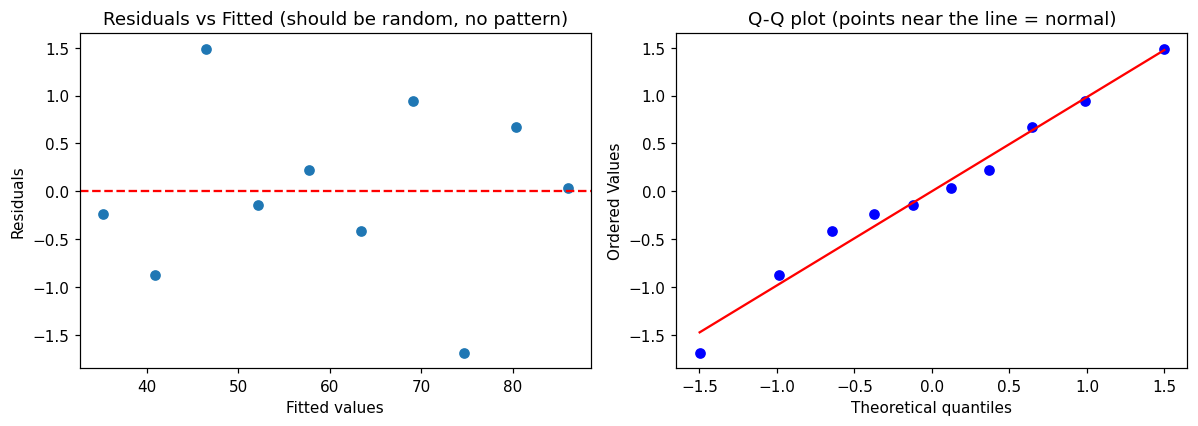

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression

X = np.arange(1, 11).reshape(-1, 1)                       # hours studied
y = np.array([35, 40, 48, 52, 58, 63, 70, 73, 81, 86])    # exam score
model = LinearRegression().fit(X, y)
fitted = model.predict(X)
residuals = y - fitted

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(fitted, residuals); ax[0].axhline(0, color="red", linestyle="--")
ax[0].set(xlabel="Fitted values", ylabel="Residuals", title="Residuals vs Fitted (should be random, no pattern)")
stats.probplot(residuals, dist="norm", plot=ax[1]); ax[1].set_title("Q-Q plot (points near the line = normal)")
plt.tight_layout(); plt.show()

print("Mean of residuals:", round(residuals.mean(), 6))
print("Shapiro-Wilk p-value:", round(stats.shapiro(residuals).pvalue, 3), "(> 0.05 -> residuals look normal)")

### **3. Write the mathematical equation for a simple linear regression model and explain each term.**

**Answer**:

**Equation**:  `Y = β₀ + β₁X + ε`

(The fitted/predicted line is `Ŷ = β₀ + β₁X`)

| Term | Meaning |
|---|---|
| **Y** | Dependent (response/target) variable, the value we want to predict |
| **X** | Independent (predictor/feature) variable |
| **β₀ (intercept)** | Value of Y when X = 0, where the line cuts the Y-axis |
| **β₁ (slope)** | Change in Y for a one-unit increase in X |
| **ε (error term)** | Random error/residual: the part of Y not explained by X (`ε = Y − Ŷ`) |

### **4. Provide a real-world example where simple linear regression can be applied.**

**Answer**:

**Predicting exam marks from hours studied**: X = hours studied per day, Y = marks scored. After fitting the line on past students, a teacher can predict the score of a student who studies 7.5 hours, and see how many extra marks each extra hour of study gives.

Other examples: house price vs. area (sq. ft.), salary vs. years of experience, sales vs. advertising spend, crop yield vs. rainfall, electricity bill vs. units consumed.

### **5. What is the method of least squares in linear regression?**

**Answer**:

The **method of least squares (Ordinary Least Squares, OLS)** finds the best-fitting line by choosing β₀ and β₁ that **minimise the sum of squared residuals (SSE)**:

`SSE = Σ (yᵢ − ŷᵢ)² = Σ (yᵢ − β₀ − β₁xᵢ)²`

Squaring makes all errors positive and penalises large errors more. Setting the derivatives to zero gives the closed-form solution:

* **Slope**: `β₁ = Σ(xᵢ − x̄)(yᵢ − ȳ) / Σ(xᵢ − x̄)²`
* **Intercept**: `β₀ = ȳ − β₁·x̄`

The resulting line always passes through the point (x̄, ȳ). The cell below computes the formulas by hand and compares them with scikit-learn.

In [2]:
import numpy as np
from sklearn.linear_model import LinearRegression

x = np.arange(1, 11)
y = np.array([35, 40, 48, 52, 58, 63, 70, 73, 81, 86])

# Least squares formulas by hand
b1 = np.sum((x - x.mean()) * (y - y.mean())) / np.sum((x - x.mean()) ** 2)
b0 = y.mean() - b1 * x.mean()
print(f"Manual (least squares):  slope = {b1:.4f}, intercept = {b0:.4f}")

sk = LinearRegression().fit(x.reshape(-1, 1), y)
print(f"scikit-learn:            slope = {sk.coef_[0]:.4f}, intercept = {sk.intercept_:.4f}")
print("SSE (minimised):", round(np.sum((y - (b0 + b1 * x)) ** 2), 4))

Manual (least squares):  slope = 5.6364, intercept = 29.6000
scikit-learn:            slope = 5.6364, intercept = 29.6000
SSE (minimised): 7.4909


### **6. What is Logistic Regression? How does it differ from Linear Regression?**

**Answer**:

**Logistic Regression** is a supervised learning algorithm used for **classification** (mostly binary: yes/no, spam/not spam, pass/fail). It applies the **sigmoid (logistic) function** to a linear combination of features to output a **probability between 0 and 1**:

`P(Y=1) = 1 / (1 + e^−(β₀ + β₁X))`

A threshold (usually 0.5) converts the probability into a class label.

| Aspect | Linear Regression | Logistic Regression |
|---|---|---|
| **Task** | Regression (predict continuous value) | Classification (predict class/probability) |
| **Output** | Any real number (−∞ to +∞) | Probability between 0 and 1 |
| **Function** | Straight line `Y = β₀ + β₁X` | S-shaped sigmoid curve |
| **Loss function** | Mean Squared Error (least squares) | Log loss (cross-entropy), fitted by maximum likelihood |
| **Target variable** | Continuous (price, marks) | Categorical (0/1) |
| **Evaluation** | MAE, MSE, RMSE, R² | Accuracy, precision, recall, F1, ROC-AUC |
| **Example** | Predict marks from study hours | Predict pass/fail from study hours |

In [3]:
import numpy as np
from sklearn.linear_model import LogisticRegression

hours = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10]).reshape(-1, 1)
passed = np.array([0, 0, 0, 0, 1, 0, 1, 1, 1, 1])        # 0 = fail, 1 = pass

clf = LogisticRegression().fit(hours, passed)
for h in [2, 5, 8]:
    p = clf.predict_proba([[h]])[0, 1]
    print(f"Study hours = {h}: P(pass) = {p:.2f} -> predicted class = {clf.predict([[h]])[0]}")

Study hours = 2: P(pass) = 0.04 -> predicted class = 0
Study hours = 5: P(pass) = 0.39 -> predicted class = 0
Study hours = 8: P(pass) = 0.91 -> predicted class = 1


### **7. Name and briefly describe three common evaluation metrics for regression models.**

**Answer**:

**1. Mean Absolute Error (MAE)**: average of the absolute differences between actual and predicted values.
`MAE = (1/n) Σ |yᵢ − ŷᵢ|`. It is in the same unit as Y, easy to interpret and not very sensitive to outliers.

**2. Mean Squared Error (MSE)**: average of the squared errors.
`MSE = (1/n) Σ (yᵢ − ŷᵢ)²`. It penalises large errors heavily (sensitive to outliers); unit is the square of Y's unit.

**3. Root Mean Squared Error (RMSE)**: square root of MSE.
`RMSE = √MSE`. It is in the same unit as Y and gives a typical size of the prediction error, with extra weight on large errors.

*(Another very common metric is **R²**, explained in Question 8.)*

In [4]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

X = np.arange(1, 11).reshape(-1, 1)
y = np.array([35, 40, 48, 52, 58, 63, 70, 73, 81, 86])
y_pred = LinearRegression().fit(X, y).predict(X)

mae = mean_absolute_error(y, y_pred)
mse = mean_squared_error(y, y_pred)
rmse = np.sqrt(mse)
print(f"MAE  = {mae:.4f}")
print(f"MSE  = {mse:.4f}")
print(f"RMSE = {rmse:.4f}")

MAE  = 0.6727
MSE  = 0.7491
RMSE = 0.8655


### **8. What is the purpose of the R-squared metric in regression analysis?**

**Answer**:

**R-squared (R², coefficient of determination)** tells **how much of the variation in the target variable Y is explained by the model** (the independent variable(s)).

`R² = 1 − SSE / SST = 1 − Σ(yᵢ − ŷᵢ)² / Σ(yᵢ − ȳ)²`

* **R² = 1**: model explains all the variance (perfect fit).
* **R² = 0**: model is no better than simply predicting the mean of Y.
* **R² < 0**: model is worse than predicting the mean (possible on test data).
* *Example*: R² = 0.85 means 85% of the variation in marks is explained by study hours.

🔹 **Purpose**: to judge the goodness of fit and to compare models on the same data.
🔹 **Limitations**: R² never decreases when more features are added, so use **Adjusted R²** for multiple regression; a high R² does not prove causation or that the model is correct, so also check residual plots.

In [5]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

X = np.arange(1, 11).reshape(-1, 1)
y = np.array([35, 40, 48, 52, 58, 63, 70, 73, 81, 86])
y_pred = LinearRegression().fit(X, y).predict(X)

sse = np.sum((y - y_pred) ** 2)
sst = np.sum((y - y.mean()) ** 2)
print("R2 (manual)       :", round(1 - sse / sst, 4))
print("R2 (scikit-learn) :", round(r2_score(y, y_pred), 4))

R2 (manual)       : 0.9972
R2 (scikit-learn) : 0.9972


# **PRACTICAL QUESTIONS**

### **9. Write Python code to fit a simple linear regression model using scikit-learn and print the slope and intercept.**

**Answer**:

Slope (coefficient)  : 5.6364
Intercept            : 29.6
R-squared            : 0.9972
Prediction for 7.5 hours: 71.87


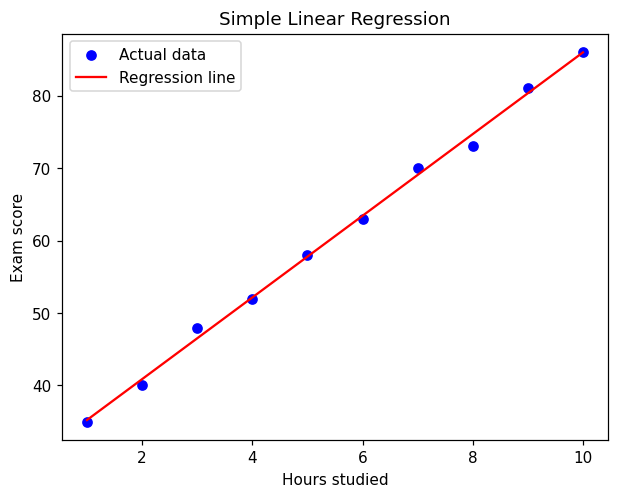

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Sample data: hours studied (X) vs exam score (y)
X = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10]).reshape(-1, 1)   # must be 2D for sklearn
y = np.array([35, 40, 48, 52, 58, 63, 70, 73, 81, 86])

# Fit the model
model = LinearRegression()
model.fit(X, y)

# Print slope (coefficient) and intercept
print("Slope (coefficient)  :", round(model.coef_[0], 4))
print("Intercept            :", round(model.intercept_, 4))
print("R-squared            :", round(r2_score(y, model.predict(X)), 4))
print("Prediction for 7.5 hours:", round(model.predict([[7.5]])[0], 2))

# Visualize
plt.scatter(X, y, color="blue", label="Actual data")
plt.plot(X, model.predict(X), color="red", label="Regression line")
plt.xlabel("Hours studied"); plt.ylabel("Exam score")
plt.title("Simple Linear Regression"); plt.legend(); plt.show()

### **10. How do you interpret the coefficients in a simple linear regression model?**

**Answer**:

Using the model fitted in Question 9: **Score = 29.60 + 5.64 × Hours**

* **Slope (β₁ = 5.64)**: for every **one extra hour of study**, the predicted exam score increases by about **5.64 marks**, on average. A **positive** slope means X and Y move in the same direction; a **negative** slope means they move in opposite directions; a slope near **0** means little linear relationship.
* **Intercept (β₀ = 29.60)**: the predicted score when hours studied = 0. It is the starting level of the line. It is meaningful only if X = 0 is inside or close to the observed data range; otherwise it is just a mathematical anchor (here the data starts at 1 hour, so this is an extrapolation).

🔹 **Things to remember**
* The slope shows **association, not necessarily causation**.
* Interpretation is valid only within the range of X seen in the data (1 to 10 hours here); do not extrapolate far beyond it.
* The units matter: the slope is in *marks per hour*.
* Use the p-value/confidence interval of β₁ (e.g. with `statsmodels`) to check whether the slope is statistically significant.